In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [8]:
df=pd.read_csv("Student_Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
df["Extracurricular Activities"]=df["Extracurricular Activities"].map({"Yes":1,"No":0})


   Hours Studied  ...  Performance Index
0              7  ...               91.0
1              4  ...               65.0
2              8  ...               45.0
3              5  ...               36.0
4              7  ...               66.0

[5 rows x 6 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB
None
       Hours Studied  ...  Performance Index
count  

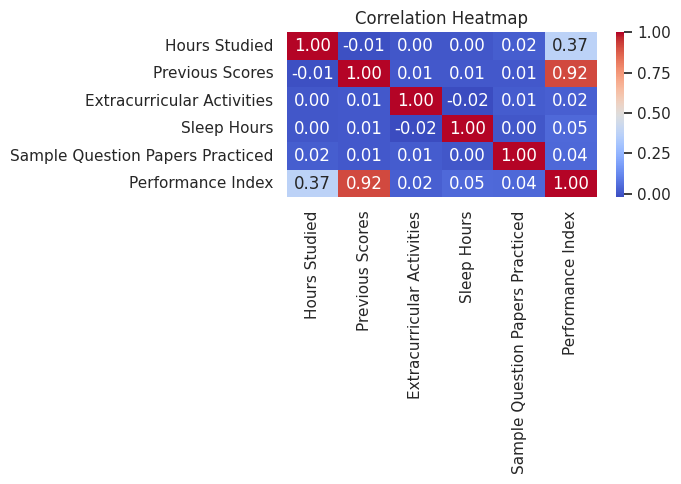

In [10]:
plt.figure(figsize=(7,5))
sns.heatmap(df.corr(),annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()



=== SIMPLE LINEAR REGRESSION ===
Intercept (b0): 41.436634826535744
Slope (b1)    : 2.784300441170774
R2   : 0.13160425385996788
RMSE : 17.93919001285204


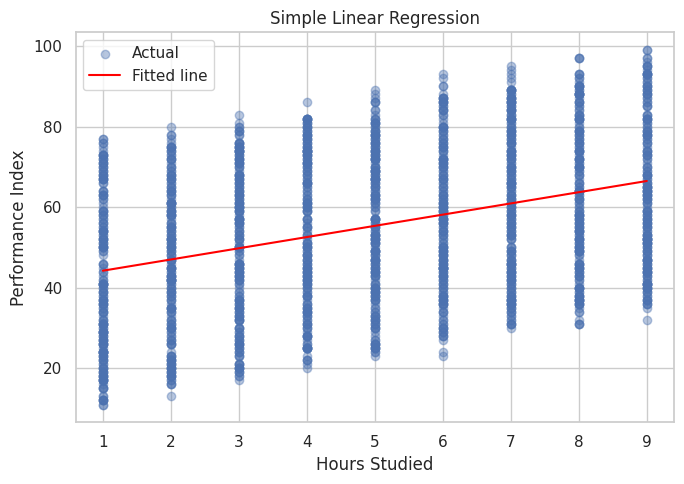

In [12]:
X_simple = df[["Hours Studied"]]  # 2D (DataFrame) because sklearn wants it
y = df["Performance Index"]      # 1D target

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(Xs_train, ys_train)

print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Intercept (b0):", simple_model.intercept_)
print("Slope (b1)    :", simple_model.coef_[0])
ys_pred = simple_model.predict(Xs_test)
print("R2   :", r2_score(ys_test, ys_pred))
print("RMSE :", np.sqrt(mean_squared_error(ys_test, ys_pred)))

# Plot the fitted line
plt.figure(figsize=(7, 5))
plt.scatter(Xs_test, ys_test, alpha=0.4, label="Actual")
plt.plot(
    Xs_test.sort_values("Hours Studied"),
    simple_model.predict(Xs_test.sort_values("Hours Studied")),
    color="red",
    label="Fitted line"
)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_linear.png")
plt.show()

In [13]:
X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept:", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"  {name:35s} {coef:.4f}")
y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print("R2          :", r2)
print("Adjusted R2 :", adj_r2)
print("RMSE        :", rmse)


=== MULTIPLE LINEAR REGRESSION ===
Intercept: -33.92194621555638
  Hours Studied                       2.8525
  Previous Scores                     1.0170
  Extracurricular Activities          0.6086
  Sleep Hours                         0.4769
  Sample Question Papers Practiced    0.1918
R2          : 0.9889832909573145
Adjusted R2 : 0.9889556663107681
RMSE        : 2.0205515085050054



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:57:21   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const 

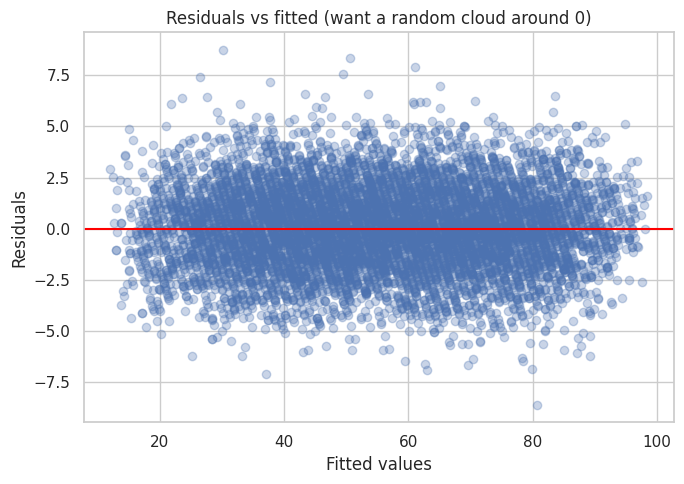

In [16]:
X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
ola=sm.OLS(y_train,X_train_sm).fit()
print("\n",ols.summary())
fitted=ols.fittedvalues
resid=ols.resid
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()



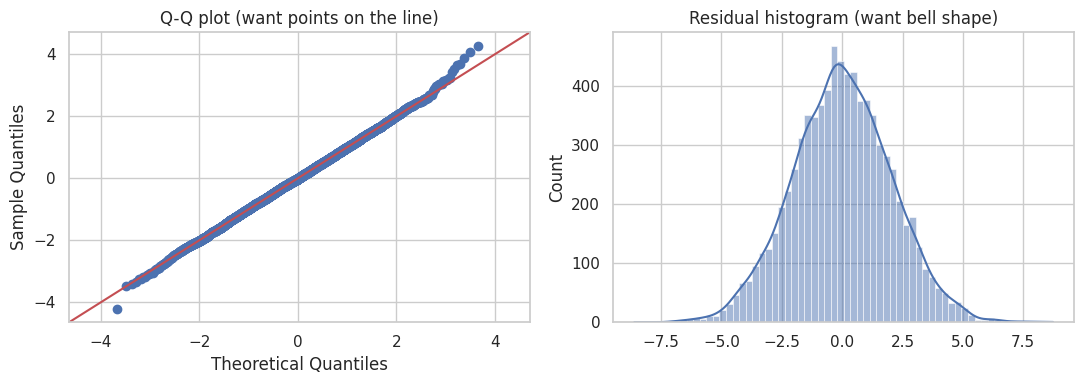

In [17]:
# 5b. Normality of residuals: Q-Q plot + histogram
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()


In [18]:
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)

Breusch-Pagan p-value: 0.2396245087908097


In [19]:
print("Durbin-Watson:", durbin_watson(resid))

Durbin-Watson: 2.0331060225040156


In [20]:
vif = pd.DataFrame()
vif["Feature"] = X_train_sm.columns
vif["VIF"] = [variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])]
print(f"\nVIF:\n", vif[vif["Feature"] != "const"])


VIF:
                             Feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


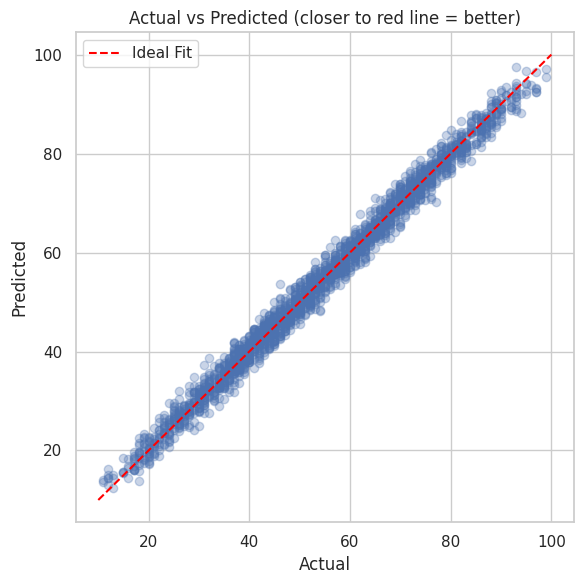

In [21]:
plt.figure(figsize=(6, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--", label="Ideal Fit")

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.legend()
plt.tight_layout()

plt.savefig("05_actual_vs_pred.png")
plt.show()